In [49]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
data_path = Path("../raw/used_cars_cleaned.csv")
df = pd.read_csv(data_path)
print("Dataset shape:", df.shape)
display(df.head())



Dataset shape: (4009, 14)


,brand,model,model_year,milage,fuel_type,ext_col,int_col,accident,clean_title,price,horsepower,engine_size,cylinders,transmission_type
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,Black,Black,1,Yes,10300.0,300.0,3.7,6.0,Automatic
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,Moonlight Cloud,Gray,1,Yes,38005.0,NaN,3.8,6.0,Automatic
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,Blue,Black,0,NaN,54598.0,NaN,NaN,NaN,Automatic
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,Black,Black,0,Yes,15500.0,354.0,3.5,6.0,Automatic
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,Glacier White Metallic,Black,0,NaN,34999.0,NaN,2.0,4.0,Automatic


In [50]:
df.info()
display(df.describe())
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df["price"].describe())

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   brand              4009 non-null   str    
 1   model              4009 non-null   str    
 2   model_year         4009 non-null   int64  
 3   milage             4009 non-null   float64
 4   fuel_type          3964 non-null   str    
 5   ext_col            4009 non-null   str    
 6   int_col            4009 non-null   str    
 7   accident           4009 non-null   int64  
 8   clean_title        3413 non-null   str    
 9   price              4009 non-null   float64
 10  horsepower         3201 non-null   float64
 11  engine_size        3634 non-null   float64
 12  cylinders          3569 non-null   float64
 13  transmission_type  4009 non-null   str    
dtypes: float64(5), int64(2), str(7)
memory usage: 438.6 KB


,model_year,milage,accident,price,horsepower,engine_size,cylinders
count,4009.000000,4009.000000,4009.000000,4.009000e+03,3201.000000,3634.000000,3569.000000
mean,2015.515590,64717.551010,0.245947,4.455319e+04,332.206498,3.709397,6.219109
std,6.104816,52296.599459,0.430701,7.871064e+04,122.258492,1.423903,1.706018
min,1974.000000,100.000000,0.000000,2.000000e+03,70.000000,0.650000,3.000000
25%,2012.000000,23044.000000,0.000000,1.720000e+04,248.000000,2.500000,4.000000
50%,2017.000000,52775.000000,0.000000,3.100000e+04,310.000000,3.500000,6.000000
75%,2020.000000,94100.000000,0.000000,4.999000e+04,400.000000,4.700000,8.000000
max,2024.000000,405000.000000,1.000000,2.954083e+06,1020.000000,8.400000,12.000000


brand                  0
model                  0
model_year             0
milage                 0
fuel_type             45
ext_col                0
int_col                0
accident               0
clean_title          596
price                  0
horsepower           808
engine_size          375
cylinders            440
transmission_type      0
dtype: int64
Duplicates: 0
count    4.009000e+03
mean     4.455319e+04
std      7.871064e+04
min      2.000000e+03
25%      1.720000e+04
50%      3.100000e+04
75%      4.999000e+04
max      2.954083e+06
Name: price, dtype: float64


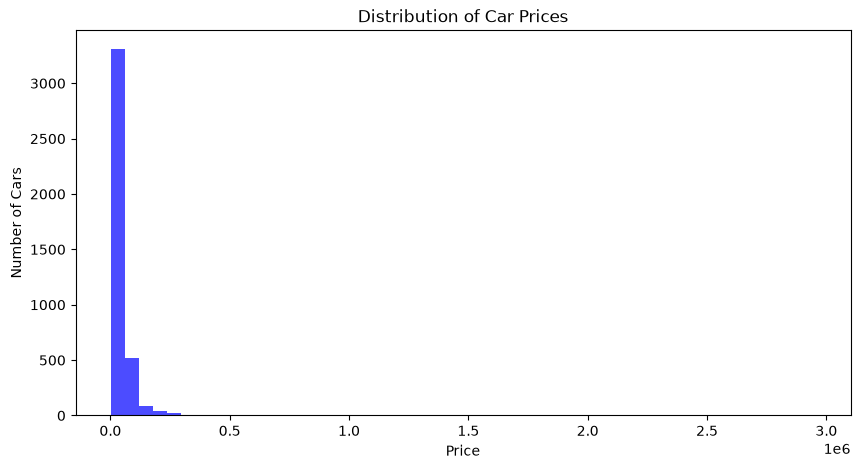

In [51]:
plt.figure(figsize=(10, 5))
plt.hist(df["price"], bins=50, color='blue', alpha=0.7)
plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Number of Cars")
plt.show()

C:\Users\manna\AppData\Local\Temp\ipykernel_15644\2972290509.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["price"], vert=False)


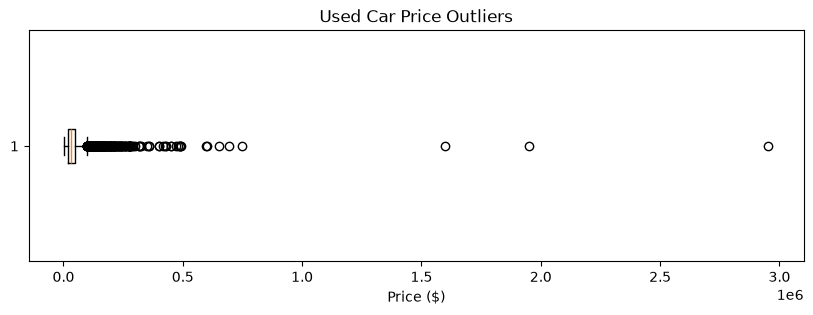

In [52]:

plt.figure(figsize=(10, 3))

plt.boxplot(df["price"], vert=False)

plt.title("Used Car Price Outliers")
plt.xlabel("Price ($)")

plt.show()


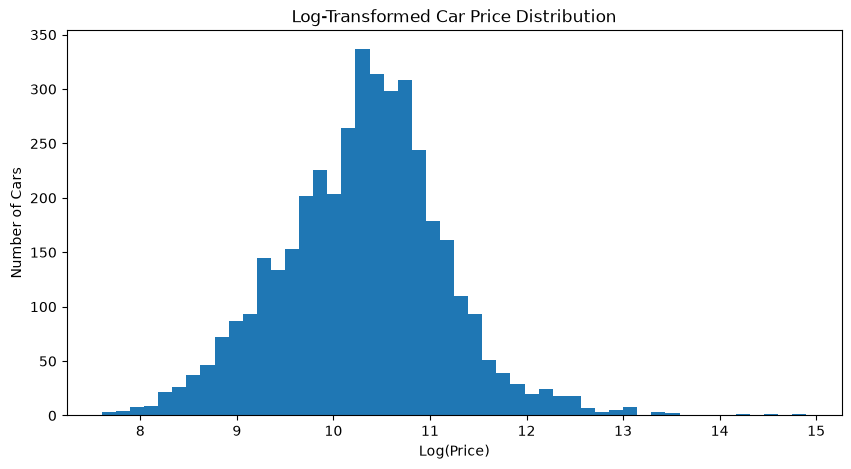

In [53]:

plt.figure(figsize=(10, 5))

plt.hist(np.log1p(df["price"]), bins=50)

plt.title("Log-Transformed Car Price Distribution")
plt.xlabel("Log(Price)")
plt.ylabel("Number of Cars")

plt.show()



In [54]:
# Separate features (X) and target (y)

X = df.drop(columns=["price"])

# Log-transform the target variable
y = np.log1p(df["price"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(y.head())

Features shape: (4009, 13)
Target shape: (4009,)


0     9.239996
1    10.545499
2    10.907771
3     9.648660
4    10.463103
Name: price, dtype: float64

In [55]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (3207, 13)
Testing features: (802, 13)
Training target: (3207,)
Testing target: (802,)


In [56]:

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numerical_features
]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['model_year', 'milage', 'accident', 'horsepower', 'engine_size', 'cylinders']
Categorical features: ['brand', 'model', 'fuel_type', 'ext_col', 'int_col', 'clean_title', 'transmission_type']


In [57]:
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [58]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (3207, 2117)
Testing shape: (802, 2117)


In [59]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

In [60]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [61]:

y_pred = model.predict(X_test)

print("First 10 predictions (log prices):")
print(y_pred[:10])

First 10 predictions (log prices):
[10.25919732  9.46429093 10.92576628 10.65088473 10.61498054 10.22025713
 10.49396383 10.38500044  9.33818751  9.25968576]


In [62]:

y_test_dollars = np.expm1(y_test)
y_pred_dollars = np.expm1(y_pred)

results = pd.DataFrame({
    "Actual Price": y_test_dollars,
    "Predicted Price": y_pred_dollars
})

display(results.head(10))

,Actual Price,Predicted Price
2580,28000.0,28542.865507
3660,5900.0,12890.080664
897,41000.0,55589.426258
2091,40250.0,42228.940027
1044,77999.0,40739.605087
2320,35899.0,27452.724698
465,36000.0,36095.956233
196,47214.0,32369.423878
3113,30900.0,11362.792803
3553,11000.0,10504.831516


In [63]:
mae = mean_absolute_error(y_test_dollars, y_pred_dollars)

rmse = np.sqrt(
    mean_squared_error(y_test_dollars, y_pred_dollars)
)

r2 = r2_score(y_test_dollars, y_pred_dollars)

print("Model Evaluation:")
print("-------------------------")
print(f"MAE:  ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R2:    {r2:.4f}")

Model Evaluation:
-------------------------
MAE:  $17,767.18
RMSE: $138,280.04
R2:    0.0645


In [64]:

results = pd.DataFrame({
    "Actual": y_test_dollars,
    "Predicted": y_pred_dollars
})

results["Absolute_Error"] = abs(
    results["Actual"] - results["Predicted"]
)

# Display the 10 worst predictions
display(
    results.sort_values(
        by="Absolute_Error",
        ascending=False
    ).head(10)
)

,Actual,Predicted,Absolute_Error
693,2954083.0,17033.623097,2.937049e+06
229,1950995.0,45662.121331,1.905333e+06
3046,1599000.0,42558.337160,1.556442e+06
1061,489995.0,56367.373135,4.336276e+05
203,429998.0,20284.035695,4.097140e+05
76,359991.0,569463.284219,2.094723e+05
254,359991.0,569406.702859,2.094157e+05
1811,399900.0,217900.809899,1.819992e+05
1575,229000.0,58664.913483,1.703351e+05
450,314900.0,208601.994085,1.062980e+05


In [67]:
print("Actual test price statistics:")
display(y_test_dollars.describe())

print("Predicted price statistics:")
display(pd.Series(y_pred_dollars).describe())

Actual test price statistics:


count    8.020000e+02
mean     5.026114e+04
std      1.430562e+05
min      2.300000e+03
25%      1.727600e+04
50%      3.099950e+04
75%      4.787500e+04
max      2.954083e+06
Name: price, dtype: float64

Predicted price statistics:


count       802.000000
mean      40476.866505
std       44550.857112
min        3432.721975
25%       17941.934655
50%       31279.955845
75%       48520.332028
max      569463.284219
dtype: float64

In [66]:
mae_log = mean_absolute_error(y_test, y_pred)

rmse_log = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2_log = r2_score(y_test, y_pred)

print("Log-space evaluation:")
print(f"MAE:  {mae_log:.4f}")
print(f"RMSE: {rmse_log:.4f}")
print(f"R2:   {r2_log:.4f}")

Log-space evaluation:
MAE:  0.2505
RMSE: 0.4327
R2:   0.7595


In [68]:

worst_predictions = results.nlargest(
    10, "Absolute_Error"
)

# Retrieve their original car characteristics
worst_cars = X_test.loc[
    worst_predictions.index,
    [
        "brand",
        "model",
        "model_year",
        "milage",
        "fuel_type",
        "horsepower",
        "engine_size",
        "cylinders"
    ]
]

# Combine characteristics with prediction results
display(
    pd.concat(
        [worst_cars, worst_predictions],
        axis=1
    )
)

,brand,model,model_year,milage,fuel_type,horsepower,engine_size,cylinders,Actual,Predicted,Absolute_Error
693,Maserati,Quattroporte Base,2005,32000.0,Gasoline,394.0,4.2,8.0,2954083.0,17033.623097,2.937049e+06
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330.0,Gasoline,NaN,8.0,NaN,1950995.0,45662.121331,1.905333e+06
3046,Porsche,Carrera GT Base,2005,4400.0,Gasoline,605.0,5.7,10.0,1599000.0,42558.337160,1.556442e+06
1061,Dodge,Viper GTC,2017,1389.0,Gasoline,645.0,8.4,10.0,489995.0,56367.373135,4.336276e+05
203,Ford,GT,2005,1897.0,Gasoline,NaN,NaN,NaN,429998.0,20284.035695,4.097140e+05
76,Lamborghini,Huracan Tecnica Coupe,2023,255.0,Gasoline,NaN,5.2,NaN,359991.0,569463.284219,2.094723e+05
254,Lamborghini,Huracan Tecnica Coupe,2023,278.0,Gasoline,NaN,5.2,NaN,359991.0,569406.702859,2.094157e+05
1811,Lamborghini,Aventador LP700-4,2016,3254.0,Gasoline,NaN,6.5,12.0,399900.0,217900.809899,1.819992e+05
1575,Mercedes-Benz,Maybach S 580 4MATIC,2022,4760.0,Gasoline,NaN,4.0,8.0,229000.0,58664.913483,1.703351e+05
450,Rolls-Royce,Ghost Base,2021,850.0,Gasoline,563.0,6.7,12.0,314900.0,208601.994085,1.062980e+05
